<a href="https://colab.research.google.com/github/wonjun605/Digital-Image-Processing/blob/main/ch06_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


(256, 256, 3)


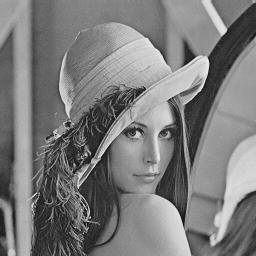

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

Img = cv2.imread('/content/gdrive/My Drive/ColabIP26/Images/lena256.jpg')
RGB_Img = cv2.cvtColor(Img, cv2.COLOR_BGR2RGB)

gImg= cv2.cvtColor(RGB_Img, cv2.COLOR_RGB2GRAY)
print(Img.shape)
cv2_imshow(gImg)

In [ ]:
gx = np.array([[-1,0],[0,1]], dtype=int)
gy = np.array([[0,-1],[1,0]], dtype=int)
print(gx)
print(gy)

[[-1  0]
 [ 0  1]]
[[ 0 -1]
 [ 1  0]]


In [ ]:
x = cv2.filter2D(gImg, -1, gx)
y = cv2.filter2D(gImg, -1, gy)


In [ ]:
absX = cv2.convertScaleAbs(x)
absY = cv2.convertScaleAbs(y)

In [ ]:
absX = absX * 3
absY = absY * 3

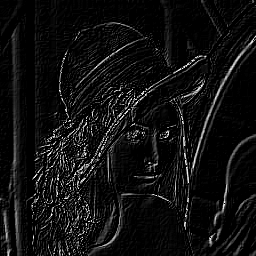

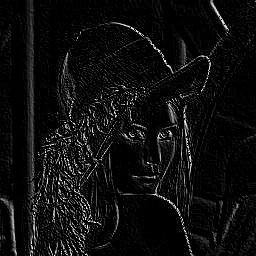

In [ ]:
cv2_imshow(absX)
cv2_imshow(absY)

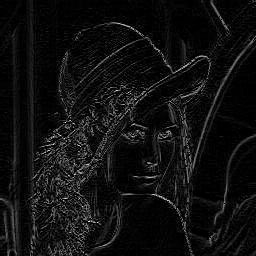

In [ ]:
outImg = cv2.addWeighted(absX, 0.5, absY, 0.5, 0)
#outImg = outImg * 5
cv2_imshow(outImg)

In [ ]:
gBin = np.zeros(gImg.shape, dtype=np.uint8)

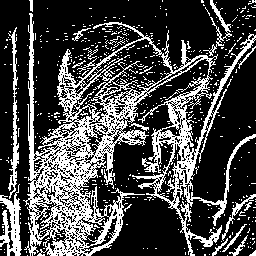

In [ ]:
threshold = 15

for h in range(gImg.shape[0]):
  for w in range(gImg.shape[1]):
    if outImg[h,w] > threshold:
      gBin[h,w] = 255

cv2_imshow(gBin)

Sobel

In [ ]:
gx = np.array([[-1,0,1],[-2,0,2],[-1,0,1]], dtype=int)
gy = np.array([[1,2,1],[0,0,0],[-1,-2,-1]], dtype=int)

In [ ]:
x = cv2.filter2D(gImg, -1, gx)
y = cv2.filter2D(gImg, -1, gy)

In [ ]:
absX = cv2.convertScaleAbs(x)
absY = cv2.convertScaleAbs(y)

In [ ]:
gBin = np.zeros(gImg.shape, dtype=np.uint8)

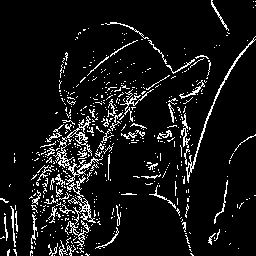

In [ ]:
threshold = 50

for h in range(gImg.shape[0]):
  for w in range(gImg.shape[1]):
    if outImg[h,w] > threshold:
      gBin[h,w] = 255

cv2_imshow(gBin)

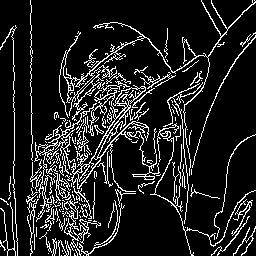

In [ ]:
cannyImg = cv2.Canny(gImg, 50, 200)
cv2_imshow(cannyImg)

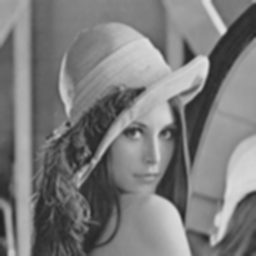

In [ ]:
blurImg = cv2.GaussianBlur(gImg, (5,5), 1.4)
cv2_imshow(blurImg)

In [ ]:
x = cv2.filter2D(blurImg, -1, gx)
y = cv2.filter2D(blurImg, -1, gy)

In [ ]:
edgeDirection = np.arctan2(y,x)
print(edgeDirection)
print(edgeDirection.shape)

[[0.    0.    0.    ... 0.    0.    0.   ]
 [1.57  1.57  1.57  ... 1.337 1.57  1.57 ]
 [1.57  1.57  1.57  ... 1.57  1.57  1.57 ]
 ...
 [1.57  1.134 0.785 ... 0.    0.    0.   ]
 [1.57  0.983 0.633 ... 0.    0.    0.   ]
 [0.    0.    0.    ... 0.    0.    0.   ]]
(256, 256)


In [ ]:
angle = np.rad2deg(edgeDirection)
print(angle)

[[ 0.    0.    0.   ...  0.    0.    0.  ]
 [90.   90.   90.   ... 76.6  90.   90.  ]
 [90.   90.   90.   ... 90.   90.   90.  ]
 ...
 [90.   64.94 45.   ...  0.    0.    0.  ]
 [90.   56.3  36.25 ...  0.    0.    0.  ]
 [ 0.    0.    0.   ...  0.    0.    0.  ]]
